# 03 · Evaluación, optimización y análisis bayesiano
1. Comparación de 7 modelos con StratifiedKFold (train vs. validación).
2. Dependencia del artista (validación agrupada).
3. Curvas de aprendizaje (sesgo/varianza).
4. Optimización: Grid vs. Random vs. **Optuna (TPE)**.
5. Probabilidad condicional y Teorema de Bayes con probabilidades calibradas *out-of-fold*.




In [ ]:
# === Solo Google Colab (en Jupyter local esta celda no hace nada) ===
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    # Ajusta esta ruta si subiste la carpeta a otro lugar de tu Drive
    RUTA_PROYECTO = "/content/drive/MyDrive/proyecto-clasificacion-musical"
    os.chdir(RUTA_PROYECTO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    # os.environ["MODO_RAPIDO"] = "1"   # descomenta para una corrida rápida (~10 min en vez de ~85)

In [1]:
# === Configuración común ===
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "funciones.py").exists())
sys.path.insert(0, str(RAIZ / "src"))
import funciones as F

warnings.filterwarnings("ignore", message=".*Early stopping criterion not reached.*")  # IterativeImputer
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
rutas = F.obtener_rutas(RAIZ)
# MODO_RAPIDO=1 (variable de entorno) reduce muestras y presupuestos para iterar rápido.
MODO_RAPIDO = os.environ.get("MODO_RAPIDO", "0") == "1"
print("Raíz:", rutas.raiz, "| modo rápido:", MODO_RAPIDO)

Raíz: <raíz> | modo rápido: False


In [2]:
X_train, X_test, y_train_txt, y_test_txt = F.cargar_conjuntos(rutas)
le, (y_train, y_test) = F.codificar_objetivo(y_train_txt, y_test_txt)
CLASES = le.classes_.tolist()
# Presupuestos de cómputo
N_CV = 3 if MODO_RAPIDO else 5
N_BUSQUEDA = 6 if MODO_RAPIDO else 30
MUESTRA = 6000 if MODO_RAPIDO else len(X_train)
idx = X_train.sample(MUESTRA, random_state=F.SEMILLA).index
Xs, ys = X_train.loc[idx].reset_index(drop=True), y_train[X_train.index.get_indexer(idx)]
cv = F.cv_estratificada(N_CV)
print(Xs.shape, CLASES)

(36958, 14) ['Alternative', 'Anime', 'Blues', 'Classical', 'Country', 'Electronic', 'Hip-Hop', 'Jazz', 'Rap', 'Rock']


## 1. Comparación de modelos
**Por qué estos modelos:** los descriptores de audio tienen relaciones no lineales (la PCA/UMAP del 01 lo mostró), interacciones (tempo × danceability) y escalas mixtas. Los árboles con boosting capturan eso sin supuestos de distribución; la logística y el Dummy fijan el piso; Naive Bayes calibrado es la referencia probabilística generativa, y el MLP representa a los modelos basados en márgenes y distancias (se prefiere a SVC-RBF, que es O(n²) con 37 000 filas y 45 clasificadores OvO). Ver `F.obtener_modelos` para los descartados.

In [3]:
modelos = F.obtener_modelos()
resultados = F.evaluar_modelos_cv(modelos, Xs, ys, cv=cv)
resultados.round(4)

✔ Dummy (prior)            F1-macro val = 0.0195  (10.3 s)


✔ Regresión Logística      F1-macro val = 0.8137  (15.1 s)


✔ GaussianNB calibrado     F1-macro val = 0.7823  (10.2 s)


✔ Random Forest            F1-macro val = 0.8172  (27.3 s)


✔ LightGBM                 F1-macro val = 0.8196  (75.8 s)


✔ XGBoost                  F1-macro val = 0.8223  (114.8 s)


✔ MLP                      F1-macro val = 0.8152  (39.9 s)


,tiempo_total_s,f1_macro_train,f1_macro_val,f1_macro_val_std,f1_macro_brecha,roc_auc_ovr_train,roc_auc_ovr_val,roc_auc_ovr_val_std,roc_auc_ovr_brecha,log_loss_train,log_loss_val,log_loss_val_std,log_loss_brecha
modelo,,,,,,,,,,,,,
XGBoost,114.8000,0.9808,0.8223,0.0029,0.1585,0.9997,0.9873,0.0005,0.0124,0.1131,0.3774,0.0094,-0.2642
LightGBM,75.8000,0.9955,0.8196,0.0035,0.1759,1.0000,0.9866,0.0005,0.0133,0.0516,0.4256,0.0122,-0.3739
Random Forest,27.3000,0.9719,0.8172,0.0035,0.1547,0.9994,0.9870,0.0005,0.0125,0.1856,0.4118,0.0073,-0.2262
MLP,39.9000,0.8849,0.8152,0.0056,0.0697,0.9942,0.9856,0.0006,0.0086,0.2544,0.4202,0.0134,-0.1658
Regresión Logística,15.1000,0.8732,0.8137,0.0028,0.0595,0.9927,0.9847,0.0005,0.0080,0.2900,0.4341,0.0084,-0.1441
GaussianNB calibrado,10.2000,0.8463,0.7823,0.0043,0.0640,0.9732,0.9557,0.0020,0.0175,0.6014,0.8067,0.0151,-0.2053
Dummy (prior),10.3000,0.0195,0.0195,0.0000,0.0000,0.5000,0.5000,0.0000,0.0000,2.2999,2.2999,0.0000,-0.0000


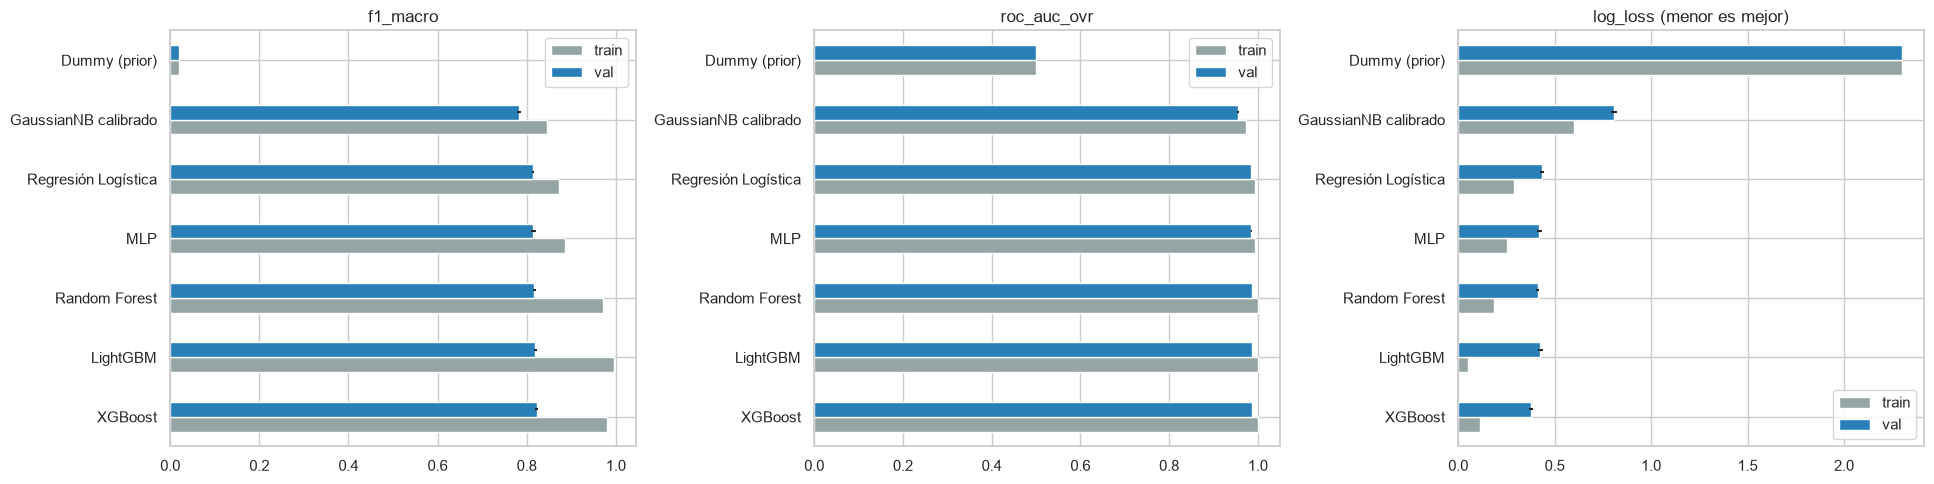

In [4]:
fig = F.grafico_train_vs_val(resultados)

**Cómo leer la tabla (sesgo–varianza):**
* **Dummy** fija el piso: F1 ≈ 0.02 y log-loss = H(y) ≈ ln 10 ≈ 2.30. Cualquier modelo útil debe estar muy por encima.
* **RF, XGBoost y LightGBM** con valores por defecto llegan a F1 de train ≈ 1: memorizan (alta varianza). Sus F1 de validación quedan a ~1 desviación estándar entre sí, así que **con los valores por defecto ninguno gana claramente**. El log-loss de validación del LightGBM sin regularizar es alto (predice con exceso de confianza), y por eso hay que optimizarlo.
* **GaussianNB** tiene el mayor sesgo: el supuesto de independencia se rompe en el bloque energy–loudness–acousticness.
* La **logística** queda cerca de los ensambles gracias al Target Encoding del artista: buena parte de la señal es "lineal" en P(género | artista). El análisis siguiente lo confirma.

## 2. ¿Cuánto depende el modelo de memorizar artistas?
Escenario de negocio: ¿clasificar el **catálogo existente** (artistas conocidos) o **lanzamientos de artistas nuevos**? Se compara StratifiedKFold con StratifiedGroupKFold agrupado por artista.

In [5]:
from lightgbm import LGBMClassifier
lgbm_base = modelos["LightGBM"]
F.evaluar_dependencia_artista(lgbm_base, Xs, ys, n_splits=N_CV).round(4)

,f1_macro,std
escenario,,
Artistas conocidos · con artista (target),0.8201,0.0031
Artistas conocidos · sin artista,0.6065,0.0048
Artistas nuevos · con artista (target),0.5402,0.0055
Artistas nuevos · sin artista,0.5945,0.0040


**Lectura:** es el hallazgo más importante del proyecto para el negocio.
* Con artistas conocidos, el Target Encoding sube el F1-macro unos **21 puntos** frente al modelo sin artista (presupuesto completo: 0.820 vs. 0.607).
* Con **artistas nuevos** esa ventaja desaparece, e incluso resta (0.540 con artista vs. 0.595 sin él): el encoder devuelve la prior y agrega ruido. El rendimiento cae al del modelo puramente acústico (~0.59–0.60), que es **el techo real de la señal de audio** con estas variables.

**Recomendación:** reportar ambas cifras. Para catalogar música de artistas ya conocidos se usa el modelo con artista. Para lanzamientos de artistas nuevos se usa el modelo sin artista, que el entrenamiento final también serializa.

## 3. Curvas de aprendizaje

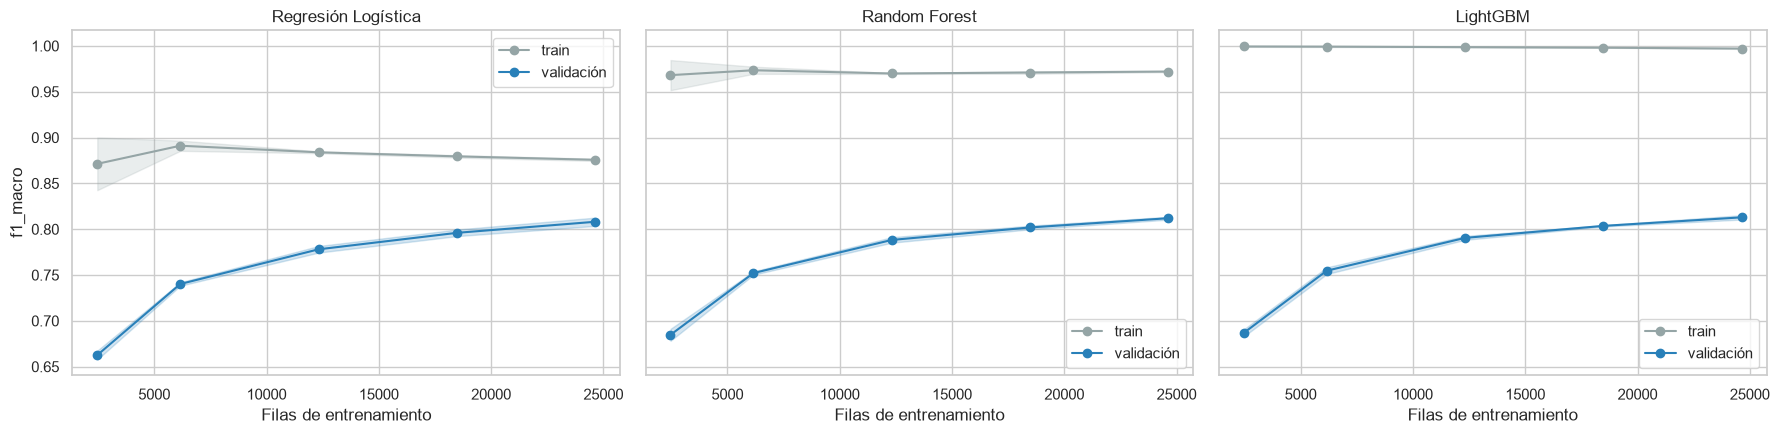

In [6]:
curvas = {n: F.construir_pipeline(modelos[n]) for n in ["Regresión Logística", "Random Forest", "LightGBM"]}
fig = F.grafico_curvas_aprendizaje(curvas, Xs, ys, cv=F.cv_estratificada(3))

**Cómo leerlas:**
* **Logística:** si las curvas convergen pronto, domina el sesgo y más datos no la mejorarán.
* **RF / LightGBM:** si train se mantiene ≈ 1 en todos los tamaños, domina la varianza. Si la validación sigue subiendo al 100 % de los datos, todavía faltan datos o regularización (`min_child_samples`, `reg_lambda`, `subsample`). Eso es justo lo que ajusta la búsqueda siguiente.

## 4. Optimización de hiperparámetros
### 4.1 Rejilla (GridSearchCV): solo para espacios pequeños
* `var_smoothing` (GaussianNB): σ²_k ← σ²_k + ε·max_j σ²_j. Con ε↑ las gaussianas se ensanchan y las fronteras cuadráticas se suavizan (menos varianza, más sesgo).
* `C` (logística): minimiza ‖w‖²/2 + C·Σ log-loss. C↑ = menos regularización, frontera más ajustada a train.

In [7]:
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
r_nb = F.busqueda_rejilla(F.construir_pipeline(GaussianNB()), Xs, ys,
                          {"clf__var_smoothing": np.logspace(-11, -1, 6 if MODO_RAPIDO else 11)}, cv=cv)
r_lr = F.busqueda_rejilla(F.construir_pipeline(LogisticRegression(max_iter=3000)), Xs, ys,
                          {"clf__C": np.logspace(-3, 2, 4 if MODO_RAPIDO else 6)}, cv=cv)
pd.DataFrame([{**r_nb.resumen(), **r_nb.mejores_parametros}, {**r_lr.resumen(), **r_lr.mejores_parametros}],
             index=["GaussianNB", "LogReg"])

,estrategia,mejor_f1_macro_cv,evaluaciones,segundos,clf__var_smoothing,clf__C
GaussianNB,Grid Search,0.7871,11,35.9000,0.0100,NaN
LogReg,Grid Search,0.8150,6,51.1000,NaN,100.0000


### 4.2 LightGBM: búsqueda aleatoria vs. optimización bayesiana (mismo presupuesto)
Con 8 hiperparámetros, una rejilla de 5 valores por eje necesitaría 5⁸ ≈ 390 000 evaluaciones. La **búsqueda aleatoria** explora con *n* evaluaciones *n* valores distintos de cada eje. La **optimización bayesiana (TPE)** además *aprende*: modela l(θ) = p(θ | score en el top-γ) y g(θ) = p(θ | resto), y propone el θ que maximiza l(θ)/g(θ) ∝ Mejora Esperada. Así reparte el presupuesto entre explorar y explotar.

In [8]:
pipe_lgbm = F.construir_pipeline(LGBMClassifier(subsample_freq=1, random_state=F.SEMILLA, verbose=-1, n_jobs=-1))
cv_busqueda = F.cv_estratificada(3)
r_rand = F.busqueda_aleatoria(pipe_lgbm, Xs, ys, n_iter=N_BUSQUEDA, cv=cv_busqueda)
r_bayes, estudio = F.busqueda_bayesiana(pipe_lgbm, Xs, ys, n_trials=N_BUSQUEDA, cv=cv_busqueda)
pd.DataFrame([r_rand.resumen(), r_bayes.resumen()]).set_index("estrategia")

,mejor_f1_macro_cv,evaluaciones,segundos
estrategia,,,
Random Search,0.8178,30,2644.8000
Optuna (TPE),0.8194,30,1018.4000


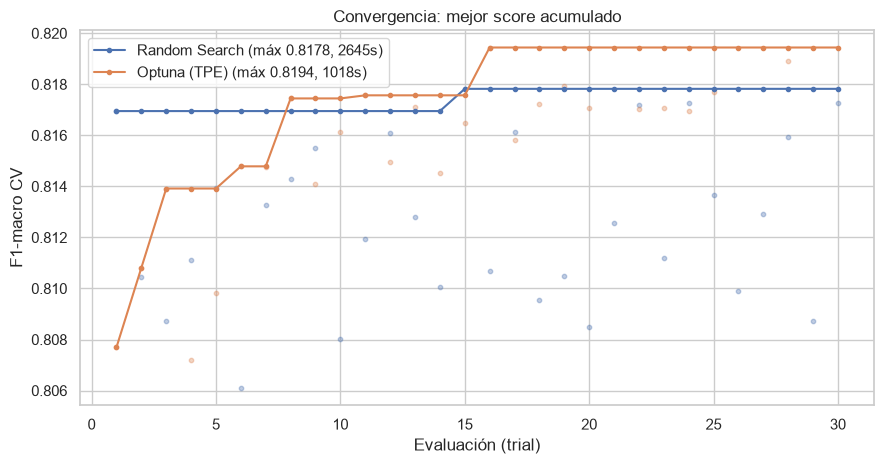

In [9]:
fig = F.grafico_convergencia([r_rand, r_bayes])

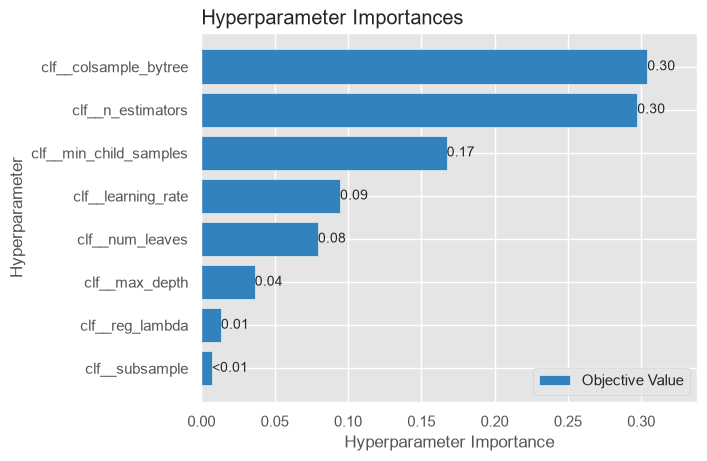

In [10]:
import optuna.visualization.matplotlib as ovm
try:
    ovm.plot_param_importances(estudio); plt.show()
except Exception as e:  # requiere >1 trial completo
    print("Importancias de hiperparámetros no disponibles:", e)

In [11]:
mejor = max([r_rand, r_bayes], key=lambda r: r.mejor_score)
print("Ganador:", mejor.estrategia)
F.tabla_significado(mejor.mejores_parametros)

Ganador: Optuna (TPE)


,valor,significado
hiperparámetro,,
n_estimators,295.0000,Nº de árboles M en F_M(x)=Σ η·f_m(x). Más árbo...
learning_rate,0.0173,Shrinkage η: cada árbol corrige solo una fracc...
num_leaves,54.0000,Hojas por árbol = nº de regiones en que cada á...
max_depth,6.0000,Profundidad máxima: orden máximo de interacció...
min_child_samples,105.0000,Mínimo de filas por hoja: regulariza fronteras...
subsample,0.5788,Fracción de filas por árbol (boosting estocást...
colsample_bytree,0.8576,Fracción de columnas por árbol: obliga a usar ...
reg_lambda,0.6754,Penalización L2 sobre los pesos de las hojas: ...


**Random vs. bayesiana.** Con el presupuesto completo (30 evaluaciones, 3 folds) TPE gana en F1 (0.8194 vs. 0.8178), pero la diferencia está dentro del error de CV. Lo decisivo es el **costo**: TPE tardó ~17 min frente a ~44 min de Random Search (2.6× más rápido), porque el *MedianPruner* corta los trials que van peor que la mediana tras el primer fold y TPE concentra el muestreo en la región prometedora (`learning_rate` bajo, árboles poco profundos y `min_child_samples` alto). En modo rápido (6 trials) ambas son equivalentes: los primeros 8 trials de TPE son aleatorios (`n_startup_trials`).

**Selección del modelo final: LightGBM optimizado.**
1. Con los valores por defecto los tres ensambles empatan (XGBoost 0.822, LightGBM 0.820, RF 0.817, std ≈ 0.003), pero los tres sobreajustan: hay una brecha train/val de 0.15–0.18 en F1, y LightGBM llega a un log-loss de 0.05 en train contra 0.43 en validación. Una vez optimizado, LightGBM baja el log-loss OOF a **0.371** (era 0.426), mejor que XGBoost por defecto (0.377): la regularización (`min_child_samples`=105, `max_depth`=6, `learning_rate`≈0.017) corrige su exceso de confianza.
2. Es el que se entrena más rápido por punto de F1, lo que permite usar el presupuesto de búsqueda.
3. El modelo serializado pesa poco y predice en microsegundos. RF pesa cientos de MB y el MLP es más sensible a la semilla.

Los parámetros se guardan para `modelo/entrenamiento_final.ipynb`.

In [12]:
resultados.round(4).to_csv(rutas.modelo / "comparacion_modelos_cv.csv")

## 5. Enfoque bayesiano y probabilidad condicional
$$P(A\mid B)=\frac{P(B\mid A)\,P(A)}{P(B)}$$
* **P(A)**: prior (frecuencia del género). **P(B|A)**: verosimilitud (qué tan típico es el rasgo B dentro del género). **P(B)**: evidencia.
* Cada probabilidad empírica lleva un **intervalo de credibilidad** Beta-Binomial (prior Beta(1, 1)): la posterior de θ = P(A|B) es Beta(1 + k, 1 + n − k).

Se calcula sobre **train** (el test queda reservado).

In [13]:
train = X_train.assign(**{F.OBJETIVO: y_train_txt.values})
preguntas = {
    "Classical | instrumentalness>0.8 & loudness<-15":
        (lambda d: d[F.OBJETIVO] == "Classical", lambda d: (d.instrumentalness > 0.8) & (d.loudness < -15)),
    "Rap | speechiness>0.33":
        (lambda d: d[F.OBJETIVO] == "Rap", lambda d: d.speechiness > 0.33),
    "Hip-Hop | speechiness>0.33":
        (lambda d: d[F.OBJETIVO] == "Hip-Hop", lambda d: d.speechiness > 0.33),
    "Electronic | instrumentalness>0.5 & danceability>0.6":
        (lambda d: d[F.OBJETIVO] == "Electronic", lambda d: (d.instrumentalness > 0.5) & (d.danceability > 0.6)),
    "Country | acousticness>0.5 & mode=Major":
        (lambda d: d[F.OBJETIVO] == "Country", lambda d: (d.acousticness > 0.5) & (d["mode"] == "Major")),
    "Anime | popularity<30 & energy>0.8":
        (lambda d: d[F.OBJETIVO] == "Anime", lambda d: (d.popularity < 30) & (d.energy > 0.8)),
}
F.tabla_bayes(train, preguntas)

,n_B,n_A∩B,P(A) prior,P(B) evidencia,P(B|A) verosimilitud,P(A|B) directa,P(A|B) vía Bayes,media posterior Beta,IC credibilidad 95%,lift P(A|B)/P(A)
pregunta,,,,,,,,,,
P(Classical | instrumentalness>0.8 & loudness<-15),2741,1974,0.1074,0.0742,0.4972,0.7202,0.7202,0.7200,"(0.7031, 0.7367)",6.7043
P(Rap | speechiness>0.33),1571,491,0.0874,0.0425,0.1520,0.3125,0.3125,0.3128,"(0.2901, 0.3359)",3.5750
P(Hip-Hop | speechiness>0.33),1571,610,0.0891,0.0425,0.1853,0.3883,0.3883,0.3884,"(0.3645, 0.4126)",4.3592
P(Electronic | instrumentalness>0.5 & danceability>0.6),2069,888,0.1061,0.0560,0.2264,0.4292,0.4292,0.4293,"(0.408, 0.4506)",4.0444
P(Country | acousticness>0.5 & mode=Major),6871,731,0.1031,0.1859,0.1918,0.1064,0.1064,0.1065,"(0.0993, 0.1139)",1.0315
P(Anime | popularity<30 & energy>0.8),2044,1295,0.1079,0.0553,0.3249,0.6336,0.6336,0.6334,"(0.6124, 0.6542)",5.8744


**Lectura:**
* Una canción muy instrumental (> 0.8) y suave (< −15 dB) es **Classical** con probabilidad alta: el *lift* frente a la prior de ~10 % es de un orden de magnitud. La verosimilitud P(B | Classical) es alta y la evidencia P(B) pequeña: el rasgo es raro fuera de la música clásica.
* `speechiness > 0.33` multiplica por ~4 la probabilidad de Rap y de Hip-Hop **por igual**: Bayes confirma que la voz hablada no distingue entre ambos.
* Los intervalos de credibilidad son estrechos donde n_B es grande y anchos donde la condición es rara. Esa es la información que una proporción puntual oculta.

### 5.1 Probabilidades del modelo: ¿están calibradas?
Para que P̂(género | x) pueda leerse como una probabilidad bayesiana tiene que estar **calibrada**. Se obtienen probabilidades *out-of-fold* del LightGBM ajustado, sin calibrar y con calibración isotónica.

In [14]:
pipe_final = F.construir_pipeline(LGBMClassifier(subsample_freq=1, random_state=F.SEMILLA, verbose=-1, n_jobs=-1)
                                  ).set_params(**mejor.mejores_parametros)
p_sin = F.probabilidades_oof(pipe_final, Xs, ys, cv=cv, calibrar=False)
p_cal = F.probabilidades_oof(pipe_final, Xs, ys, cv=cv, calibrar=True)
pd.DataFrame({"sin calibrar": F.metricas_clasificacion(ys, p_sin),
              "isotónica": F.metricas_clasificacion(ys, p_cal)}).T

,f1_macro,accuracy,roc_auc_ovr,log_loss,brier,ece
sin calibrar,0.8251,0.8356,0.9876,0.3712,0.2061,0.0135
isotónica,0.8221,0.8363,0.9873,0.3907,0.2124,0.0346


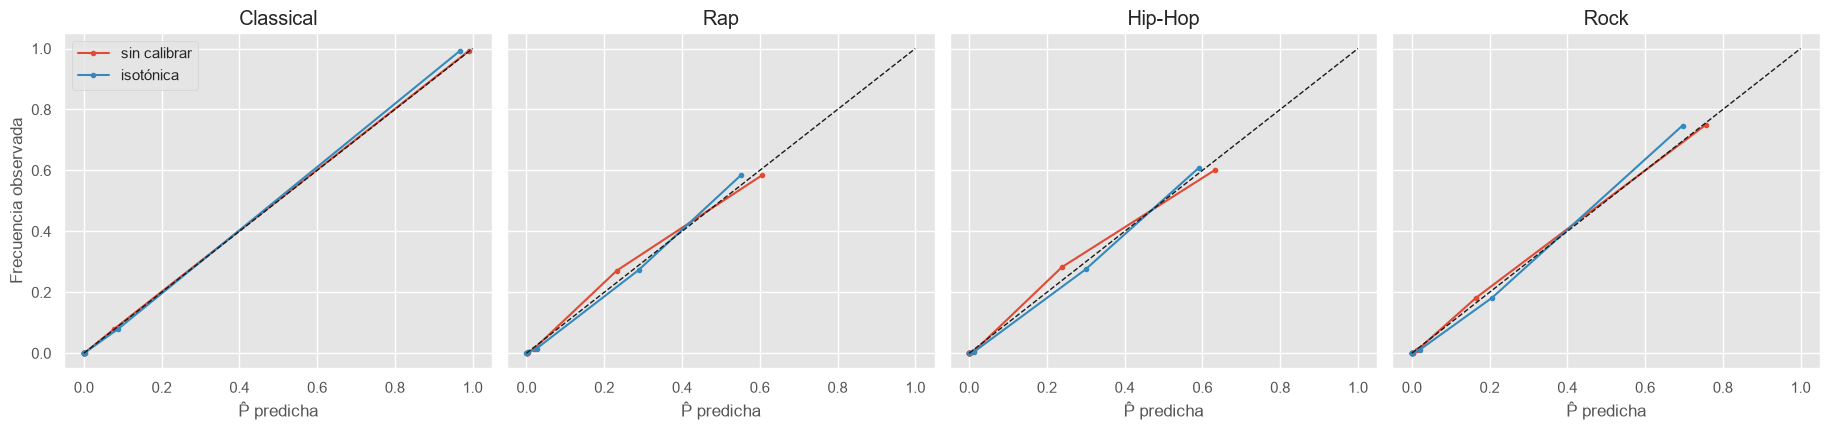

In [15]:
fig = F.grafico_confiabilidad(ys, {"sin calibrar": p_sin, "isotónica": p_cal}, CLASES,
                               ["Classical", "Rap", "Hip-Hop", "Rock"])

**Decisión de calibración (tomada con validación cruzada, no con el test):** se calibra solo si la isotónica reduce el log-loss *out-of-fold*. La isotónica es no paramétrica y necesita muchos datos por clase: con submuestras pequeñas puede empeorar el resultado (sobreajusta la función de calibración). Con el presupuesto completo **tampoco ayuda** (log-loss OOF 0.391 con calibración vs. 0.371 sin ella; ECE 0.035 vs. 0.014). El LightGBM regularizado ya está bien calibrado, así que se mantiene sin calibrar. La decisión se guarda junto con los hiperparámetros.

In [16]:
met_sin, met_cal = F.metricas_clasificacion(ys, p_sin), F.metricas_clasificacion(ys, p_cal)
CALIBRAR = met_cal["log_loss"] < met_sin["log_loss"]
p_bayes = p_cal if CALIBRAR else p_sin   # probabilidades que usa el resto de la sección
F.guardar_json({"modelo": "LightGBM", "estrategia": mejor.estrategia, "f1_macro_cv": mejor.mejor_score,
                "parametros": mejor.mejores_parametros, "calibrar_isotonica": bool(CALIBRAR),
                "log_loss_oof": {"sin_calibrar": met_sin["log_loss"], "isotonica": met_cal["log_loss"]},
                "comparacion_busquedas": [r_rand.resumen(), r_bayes.resumen()]},
               rutas.modelo / "mejores_parametros.json")
print("¿Calibrar?", CALIBRAR)

¿Calibrar? False


### 5.2 Probabilidad empírica vs. probabilidad del modelo
Si el modelo está calibrado: E[P̂(A|x) | x ∈ B] ≈ P(A|B) empírica.

In [17]:
sub_df = Xs.assign(**{F.OBJETIVO: le.inverse_transform(ys)})
condiciones = {n: (n.split(" | ")[0], fB) for n, (_, fB) in preguntas.items()}
F.comparar_empirico_vs_modelo(sub_df, p_bayes, CLASES, condiciones)

,clase,n,P(A|B) empírica,E[P̂(A|x)] modelo,P(A) prior,error_calibración
condición,,,,,,
Classical | instrumentalness>0.8 & loudness<-15,Classical,2741,0.7202,0.7204,0.1074,0.0002
Rap | speechiness>0.33,Rap,1571,0.3125,0.3038,0.0874,-0.0087
Hip-Hop | speechiness>0.33,Hip-Hop,1571,0.3883,0.3779,0.0891,-0.0104
Electronic | instrumentalness>0.5 & danceability>0.6,Electronic,2069,0.4292,0.4212,0.1061,-0.0080
Country | acousticness>0.5 & mode=Major,Country,6871,0.1064,0.1056,0.1031,-0.0008
Anime | popularity<30 & energy>0.8,Anime,2044,0.6336,0.6323,0.1079,-0.0013


**Lectura:** cuando E[P̂] ≈ P(A|B) empírica, las probabilidades del modelo pueden usarse directamente como respuesta a la pregunta de negocio, pero condicionadas a **toda** la canción y no solo a dos umbrales. En las condiciones más "puras" (Classical, Anime) el modelo suele quedarse algo por debajo de la frecuencia empírica: reparte probabilidad hacia géneros vecinos.

### 5.3 Bayes sobre las predicciones: P(género real | predicción)
Es la pregunta del usuario de negocio: *"el modelo dice Hip-Hop, ¿qué tan seguro es?"*. Es la precisión por clase expresada con Bayes: P(real = k | pred = j) = P(pred = j | real = k)·P(k) / P(pred = j).

In [18]:
pred = p_bayes.argmax(1)
tabla = pd.crosstab(pd.Series(le.inverse_transform(ys), name="real"),
                    pd.Series(le.inverse_transform(pred), name="predicho"), normalize="columns")
tabla[["Hip-Hop", "Rap", "Rock", "Alternative", "Classical"]].round(3)

predicho,Hip-Hop,Rap,Rock,Alternative,Classical
real,,,,,
Alternative,0.0350,0.0320,0.1100,0.7720,0.0000
Anime,0.0000,0.0000,0.0000,0.0030,0.0080
Blues,0.0010,0.0000,0.0240,0.0150,0.0040
Classical,0.0000,0.0000,0.0010,0.0080,0.9710
Country,0.0020,0.0100,0.0510,0.0210,0.0000
Electronic,0.0020,0.0010,0.0030,0.0080,0.0010
Hip-Hop,0.5920,0.3170,0.0180,0.0340,0.0000
Jazz,0.0060,0.0010,0.0090,0.0180,0.0160
Rap,0.3510,0.6160,0.0330,0.0250,0.0000


**Lectura:** cuando el modelo predice *Classical*, acierta ~94 % de las veces. Cuando predice *Hip-Hop* o *Rap*, el género real es el otro en ~40 % de los casos: P(real = Rap | pred = Hip-Hop) es casi tan alta como P(real = Hip-Hop | pred = Hip-Hop). Para el negocio, "Urbano" es una etiqueta confiable; la división Rap/Hip-Hop no lo es.

### 5.4 Actualización de la prior (label shift)
Una emisora de música clásica tiene una mezcla distinta: 40 % Classical y el resto repartido por igual. Sin reentrenar, Bayes corrige: P_nuevo(k|x) ∝ P̂(k|x)·π_nuevo(k)/π_train(k).

In [19]:
pi_train = np.bincount(ys, minlength=len(CLASES)) / len(ys)
pi_radio = np.full(len(CLASES), 0.6 / (len(CLASES) - 1)); pi_radio[CLASES.index("Classical")] = 0.4
p_radio = F.actualizacion_bayesiana(p_bayes, pi_train, pi_radio)
ejemplo = np.argsort(-np.abs(p_radio - p_bayes)[:, CLASES.index("Classical")])[:5]
pd.DataFrame({"P(Classical) modelo": p_bayes[ejemplo, CLASES.index("Classical")],
              "P(Classical) radio": p_radio[ejemplo, CLASES.index("Classical")],
              "género real": le.inverse_transform(ys[ejemplo])})

,P(Classical) modelo,P(Classical) radio,género real
0,0.2892,0.7101,Classical
1,0.2919,0.7127,Anime
2,0.2841,0.7049,Anime
3,0.2787,0.6993,Anime
4,0.2782,0.6988,Anime


**Lectura:** las canciones que más cambian son las ambiguas (P(Classical) intermedia, casi siempre Jazz instrumental). Con una prior de 40 % cruzan el umbral y pasan a clasificarse como Classical. Las canciones con evidencia clara no cambian: Bayes mueve la decisión solo donde los datos son ambiguos.

**Conclusión del cuadernillo:** LightGBM con los hiperparámetros ganadores es el modelo final. La decisión de calibrarlo se tomó con log-loss *out-of-fold* y queda guardada en `mejores_parametros.json`.